In [1]:
import glob
from ISRpy import beampack

jro0 = beampack.jrobeam

# from IPython import display
import random
import numpy as np

In [2]:
from OXmodeCython import OXmode_cython

In [3]:
dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmax = 800
Z = np.arange(0.01,zmax,dz)

In [4]:
training_dir = 'training_data'

d = np.load('JM91J_2016014141141.npy', allow_pickle=True)[()]
freqs = d['vipir_freqs']
hts = d['vipir_hts']

noise_dir = 'VIPIR_PROC/Dog_noise/'
noise_files = glob.glob1(noise_dir,'*.npy')
print(len(noise_files))

0


In [110]:
def fps_parabolic(a,z,beta=7):
    def softplus(x):
        return 1/beta*np.log(1+np.exp(x*beta))
    para1 = a[0]-((z-a[1])/a[2]/3)**2
    para2 = a[3]-((z-a[4])/a[5]/3)**2
    para3 = a[6]-((z-a[7])/a[8]/3)**2

    fps1 = (80.6*(softplus(para1) + softplus(para2) + softplus(para3)))**0.5
    # fps2 = (80.6*np.max(np.vstack([para1,para2,para3]), axis=0))**0.5
    return fps1#,fps2

def fps_gauss(a,z):
    result = a[0]*np.exp(-(z-a[1])**2/1000/a[2])
    result += a[3]*np.exp(-(z-a[4])**2/1000/a[5])
    return result

def sampling_fps(z, mode):
    if mode == 0:
        a = [np.random.uniform(0.75, 1.25) * 0.9,
            np.random.uniform(300, 500),
            np.random.uniform(0.75, 1.25) * 60,  
            np.random.uniform(0, 1.25) * 0.2,  
            np.random.uniform(210,320),
            np.random.uniform(0.75, 1.25) * 70,
            np.random.uniform(0, 1.25) * 0.04,
            np.random.uniform(130,170),
            np.random.uniform(0.75, 1.25) * 20]
        fps = fps_parabolic(np.array(a),z)
        foE = fps[np.argmin(np.abs(a[4] - z))]
    elif mode == 1:
        a = [random.uniform(0.75, 1.20) * 10,
            random.uniform(300, 500),
            random.uniform(0.75,1.25) * 22,  
            random.uniform(0.8,1.2) * 3.2,  
            random.uniform(100,180),
            random.uniform(0.8,1.2) * 10]
        fps = fps_gauss(np.array(a),z)
        foE = fps[np.argmin(np.abs(a[4] - z))]
    else:
        return None
    return fps,a,foE

In [111]:
# 5.6e-3*408*4
ipp = 5.6e3*0.15
print(ipp)
ipp - hts[-1]*1

840.0


66.44999999999959

In [162]:
from matplotlib import pyplot as plt
from matplotlib import rcParams
import scipy.interpolate as inter
import numpy as np
import datetime
import scipy.constants as const
import time
from skimage import morphology

from scipy.sparse import coo_matrix
from PIL import Image

def Coo2Mat(fvs,vhs, vh_start = 160):
    # Turning the output pairs from forward model to continuous traces stored in matrix
    vh_start *= np.random.uniform(0.9,1.1)
    trace_mat = np.zeros([hts.shape[0],freqs.shape[0]])
    if vhs.shape[0] == 0 or fvs.shape[0] == 0:
        return trace_mat
    ivh_prev, ifv_prev = np.argmin(np.abs(hts - vhs[0])), np.argmin(np.abs(freqs - fvs[0]))
    for (vh,fv) in zip(vhs[1:],fvs[1:]):
        if fv <= freqs.max() and fv >= freqs.min() and vh <= hts.max() and vh >= hts.min():
            ivh, ifv = np.argmin(np.abs(hts - vh)), np.argmin(np.abs(freqs - fv))
            n = max(abs(ifv_prev - ifv),abs(ivh_prev - ivh))+1
            if vh > vh_start:
                ivs = np.rint(np.linspace(ivh_prev,ivh,n)).astype(np.int_)
                ifs = np.rint(np.linspace(ifv_prev,ifv,n)).astype(np.int_)
                trace_mat[ivs, ifs] = 1
            ifv_prev,ivh_prev = ifv,ivh
    return trace_mat

def scatter_around_points(x_data : np.ndarray, y_data : np.ndarray, sigma_x, sigma_y, points=5):
    # Widen the trace
    noisy_x = [] #x_data.tolist()
    noisy_y = [] #y_data.tolist()
    M, N = freqs.shape[0], hts.shape[0]
    points = np.random.randint(3,5+1)
    for idx in range(x_data.shape[0]):
        nx = np.rint(x_data[idx] + np.random.uniform(-sigma_x,sigma_x,points))
        ny = np.rint(y_data[idx] + np.random.uniform(-sigma_y,sigma_y,points))
        valid = (ny >=0) & (ny < N) & (nx >= 0) & (nx < M)
        noisy_x += nx[valid].tolist()
        noisy_y += ny[valid].tolist()
    return np.array(noisy_x), np.array(noisy_y)

def creating_multihop(fvs, vhs, fmin = 5):
    ipp = 5.6*1e3*0.15 
    outmat = 0
    fmin_idx = np.argmin(np.abs(fvs-fmin))
    delta_vhs = np.abs(vhs[fmin_idx:]-vhs[fmin_idx-1:-1])
    fvs = np.copy(fvs[fmin_idx:])
    vhs = np.copy(vhs[fmin_idx:])
    indices = delta_vhs < 2
    for i in range(2,4):
        vhs2 = vhs*i
        for j in range(2):
            vhs2 -= ipp * j
            mh_trace = Coo2Mat(fvs[indices],vhs2[indices])
            ivhs_mh, ifvs_mh = np.nonzero(mh_trace)
            # Generate noisy data
            sigma_x = np.random.uniform(1.8,2.2)
            sigma_y = np.random.uniform(1.8,2.2)
            fvs_mh_noisy_x, vhs_mh_noisy_y = scatter_around_points(np.array(ifvs_mh), np.array(ivhs_mh), sigma_x=sigma_x, sigma_y=sigma_y)
            outmat = outmat + coo_matrix((np.ones(fvs_mh_noisy_x.shape), (vhs_mh_noisy_y,fvs_mh_noisy_x)), shape=(hts.shape[0], freqs.shape[0])).toarray()
    return outmat

def adding_holes_in_trace(noise_map, fill_rate = 0.01):
    N = int(noise_map.shape[0] * noise_map.shape[1] * fill_rate)
    loc_x = np.random.randint(0,noise_map.shape[1], N)
    loc_y = np.random.randint(0,noise_map.shape[0], N)
    hole_map = coo_matrix((np.ones(N, dtype=np.int_), (loc_y, loc_x)), shape=noise_map.shape).toarray()
    hole_map = 1 - morphology.dilation(hole_map, np.array([[0,1,0],[1,1,1],[0,1,0]]))
    noise_map *= hole_map

def gen_noise_blocks():
    M = freqs.shape[0]
    N = hts.shape[0]
    noise_x = []
    noise_y = []
    if np.random.uniform(0,1) < 1:
        for _ in range(np.random.randint(20,60)):
            r = np.random.uniform(0,1)
            if r < 0.5: # 50% small blocks
                size_x = np.random.randint(2,5)
                size_y = np.random.randint(4,7)
            elif r < 0.6: # 10% long blocks
                size_x = np.random.randint(5,10)  
                size_y = np.random.randint(30,50)
            else: # 40% wide blocks
                size_x = np.random.randint(30,50)
                size_y = np.random.randint(7,15)                        
            loc_x = np.random.randint(0,M-1)
            loc_y = np.random.randint(0,N-1)
            n = int(size_x * size_y * np.random.uniform(0.3,0.9))
            noise_x += (loc_x + np.random.uniform(-size_x/2,size_x/2,n)).astype(np.int_).tolist()
            noise_y += (loc_y + np.random.uniform(-size_y/2,size_y/2,n)).astype(np.int_).tolist()
    else :
        percent = 0.7
        noise_list = np.load(noise_dir + noise_files[np.random.randint(0, len(noise_files)-1)], allow_pickle=True)[()]['noise_list']
        random.shuffle(noise_list)
        delta_d = 100
        for cord_x, cord_y in noise_list[:int(len(noise_list) * percent)]:
            dx = np.random.randint(-delta_d,delta_d)
            dy = np.random.randint(-delta_d,delta_d)
            noise_x += (cord_x+dx).tolist()
            noise_y += (cord_y+dy).tolist()
        noise_list = np.load(noise_dir + noise_files[np.random.randint(0, len(noise_files)-1)], allow_pickle=True)[()]['noise_list']
        random.shuffle(noise_list)
        for cord_x, cord_y in noise_list[:int(len(noise_list) * (1-percent))]:
            dx = np.random.randint(-delta_d,delta_d)
            dy = np.random.randint(-delta_d,delta_d)
            noise_x += (cord_x+dx).tolist()
            noise_y += (cord_y+dy).tolist()
    
    noise_x, noise_y = np.clip(np.array(noise_x), 0, M-1), np.clip(np.array(noise_y), 0, N-1)
    noise_mat = coo_matrix((np.ones(noise_x.shape), (noise_y, noise_x)), shape=(hts.shape[0], freqs.shape[0])).toarray()

    if np.random.uniform(0,1) < 0.6:
        noise_mat = morphology.dilation(noise_mat>0, np.array([[0,1,0],[1,1,1],[1,1,1],[0,1,0]])) + 0
    return noise_mat

def remove_nosise_around_blocks(noise_map, omode, xmode):
    if np.random.uniform(0,1) < 0.85:
        mask = 1- morphology.dilation((xmode + omode)>0, np.ones([np.random.randint(4,6),np.random.randint(4,6)]))
        noise_map *= mask

def add_break_in_trace(fvs, vhs, mat, p = 0.5):
    # break_region = np.ones_like(mat)
    for _ in range(np.random.randint(0,10)):
        if np.random.uniform(0,1) > p:
            continue
        i = np.random.randint(0,fvs.shape[0]-1)
        ivh, ifv = np.argmin(np.abs(hts - vhs[i])), np.argmin(np.abs(freqs - fvs[i]))
        dx = np.random.randint(1,5)
        x1 = max(0,ifv-dx//2)
        x2 = min(ifv+dx//2, mat.shape[1])
        y1 = max(0,ivh-20//dx)
        y2 = min(ivh+20//dx, mat.shape[0])
        mat[y1:y2, x1:x2] = 0
    return mat

def add_break_at_asym_freq(asym_f, fvs, vhs, mat, p = 0.2):
    # break_region = np.ones_like(mat)
    for fa in asym_f:
        if np.random.uniform(0,1) < p:
            i = np.argmin(np.abs(fvs - fa)) - 1
            ifa = np.argmin(np.abs(freqs - fa))
            iva = np.argmin(np.abs(hts - vhs[i]))
            mat[iva-5:iva+5, ifa-5:ifa+5] = 0
    return mat

In [163]:
def graph_generate(fes, dz = 0.5, testmode = False):
    try:
        # ppparam, fes, dz = params
        rcParams['figure.subplot.right'] = 0.78
        fig,axes = plt.subplots(1,3,figsize=(21.0,6.0),sharex=True)
        ax1 = axes[0]
        fps,ppama,foe=sampling_fps(Z, mode = np.random.uniform(0,1)<0.6)
        ax1.plot(fps,Z)
        fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps,fes,dz) # x1 y1 x2 y2 

        asym_fO = []
        asym_fX = []
        for i in range(1,fvsO.shape[0]):
            if vhsO[i] - vhsO[i-1] > 80:
                asym_fO += [fvsO[i]]
        for i in range(1,fvsX.shape[0]):
            if vhsX[i] - vhsX[i-1] > 80:
                asym_fX += [fvsX[i]]

        O_trace = Coo2Mat(fvsO,vhsO)
        X_trace = Coo2Mat(fvsX,vhsX)

        ivhsO, ifvsO = np.nonzero(O_trace)
        ivhsX, ifvsX = np.nonzero(X_trace)

        # # Generate noisy data
        sigma_x = np.random.uniform(1.8,2.2)
        sigma_y = np.random.uniform(1.8,2.2)
        fvsO_noisy_x, vhsO_noisy_y = scatter_around_points(np.array(ifvsO), np.array(ivhsO), sigma_x=sigma_x, sigma_y=sigma_y)
        fvsX_noisy_x, vhsX_noisy_y = scatter_around_points(np.array(ifvsX), np.array(ivhsX), sigma_x=sigma_x, sigma_y=sigma_y)

        # print(fvsO_noisy_x.shape[0] == vhsO_noisy_y.shape[0])        
        
        omode = coo_matrix((np.ones(fvsO_noisy_x.shape), (vhsO_noisy_y,fvsO_noisy_x)), shape=(hts.shape[0], freqs.shape[0])).toarray()
        xmode = coo_matrix((np.ones(fvsX_noisy_x.shape), (vhsX_noisy_y,fvsX_noisy_x)), shape=(hts.shape[0], freqs.shape[0])).toarray()

        struct = np.array([[0,1,0],[1,1,1],[0,1,0]])
        omode = morphology.closing(omode, struct)
        xmode = morphology.closing(xmode, struct)
        
        adding_holes_in_trace(omode)
        adding_holes_in_trace(xmode)
        
        noise_map = gen_noise_blocks()
        multihop_map = creating_multihop(fvsO, vhsO, fmin=foe+1) 
        multihop_map += creating_multihop(fvsX, vhsX, fmin=foe+1)

        remove_nosise_around_blocks(noise_map, omode, xmode)
        
        add_break_in_trace(fvsO,vhsO,omode)
        add_break_in_trace(fvsX,vhsX,xmode)

        add_break_at_asym_freq(asym_fO, fvsO,vhsO,omode)
        add_break_at_asym_freq(asym_fX, fvsX,vhsX,xmode)

        omode = morphology.remove_small_objects(omode>0, min_size=10, connectivity=1)
        xmode = morphology.remove_small_objects(xmode>0, min_size=10, connectivity=1)

        omode = morphology.remove_small_holes(omode, area_threshold=10, connectivity=1)
        xmode = morphology.remove_small_holes(xmode, area_threshold=10, connectivity=1)
        
        if np.random.uniform(0,1) < 0.15: # 10% negative data
            omode = np.zeros(omode.shape, dtype=np.uint8)
            xmode = np.zeros(xmode.shape, dtype=np.uint8)
            multihop_map = np.zeros(multihop_map.shape, dtype=np.uint8)

        omode_data = np.zeros((*omode.shape,3), dtype=np.uint8)
        omode_data[:,:,0] = np.flip(omode>0,axis=0) * 255
        imgO = Image.fromarray(omode_data, 'RGB')
    
        xmode_data = np.zeros((*xmode.shape,3), dtype=np.uint8)
        xmode_data[:,:,1] = np.flip(xmode>0,axis=0) * 255
        imgX = Image.fromarray(xmode_data, 'RGB')

        ax1.pcolormesh(freqs,hts,(omode+xmode+noise_map+multihop_map)>0,shading='auto')
        axes[1].pcolormesh(freqs,hts,omode>0,shading='auto')
        for f in asym_fO: axes[1].plot([f,f],[0,700])
        axes[2].pcolormesh(freqs,hts,xmode>0,shading='auto')
        for f in asym_fX: axes[2].plot([f,f],[0,700])
        
        if testmode == True: return 
        file_name = "_".join([f"{x:.5f}" for x in ppama]) + "_.png"
        dir_name = training_dir
        fig.savefig(f"{dir_name}/visual/{file_name}", dpi=100, bbox_inches='tight', pad_inches=0, facecolor=fig.get_facecolor())
        plt.close()
        
        imgTrain = Image.fromarray(np.flip((omode+xmode+noise_map+multihop_map)>0,axis=0).astype(dtype=np.uint8)*255, 'L')
        imgTrain.save(f"{dir_name}/train/{file_name}")
        imgO.save(f"{dir_name}/O/{file_name}")
        imgX.save(f"{dir_name}/X/{file_name}")

        np.save(f"{dir_name}/asym_f/{file_name}", {'asym_fO':asym_fO, 'asym_fX':asym_fX})

    except e:
        print(e)
        pass



True


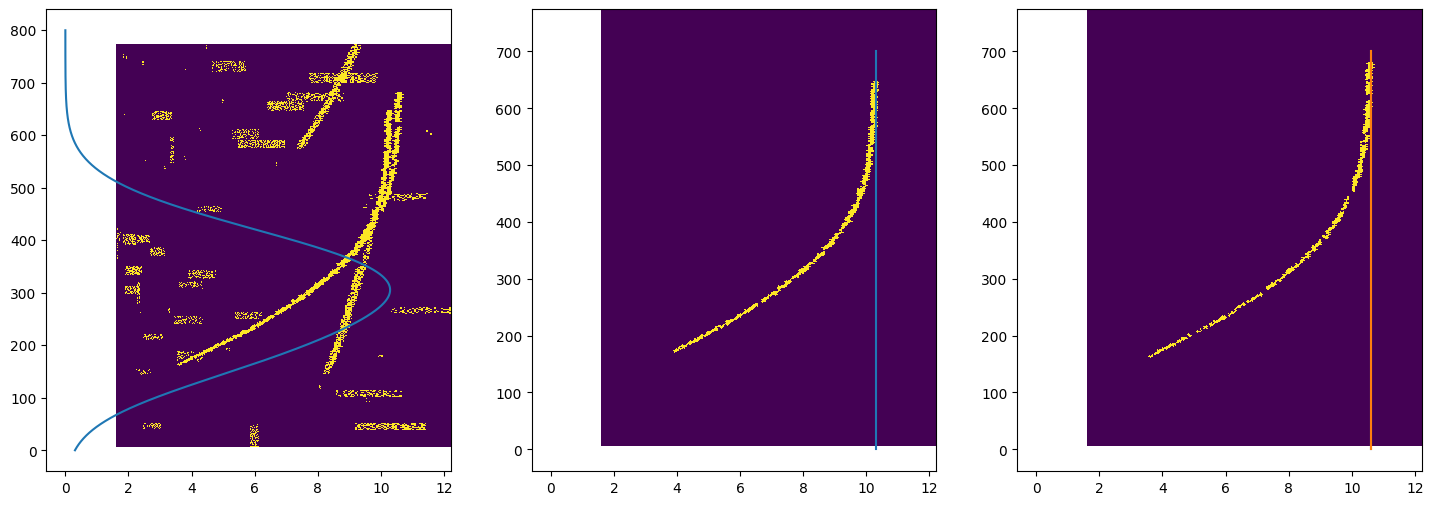

In [190]:
dt0 = datetime.datetime(2015,4,15)
igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (
        datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()
dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmax = 800
Z = np.arange(0.01,zmax,dz)
fes = []
for iZ in Z:
    r,geoc_lat,lon,aspect,B = jro0.aspect_angle(igrf_year,jro0.xyz0 + jro0.zenith0 * iZ)
    fes += [const.e * np.linalg.norm(B) * 1e-9 / const.m_e /1e6 /2/np.pi] #MHz
fes = np.array(fes)

# print(param, len(param))
graph_generate(fes,dz, testmode=True)

In [ ]:
from joblib import Parallel, delayed
import random 
import os
import multiprocessing as mp
from multiprocessing import Pool

# Generate parameters for the images [0.9,400,40,0.5,300,40,0.1,150,40]

# Use all available CPU cores to generate the graphs in parallel
Parallel(n_jobs=mp.cpu_count()-4)(delayed(graph_generate)(fes) for _ in range(20000))
# processes_pool = Pool(24)
# processes_pool.map(graph_generate, parameters)
# processes_pool.close()
# elapsed_time = time.time() - start_time
# print(f'Generated 1000 images. Time elapsed: {elapsed_time:.2f} seconds')



In [ ]:

dt0 = datetime.datetime(2015,4,15)
igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (
        datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()

dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmin = 0
zmax = 800

rcParams['figure.subplot.right'] = 0.78
#set up a plot
fig,axes = plt.subplots(1,1,figsize=(9.0,8.0),sharex=True)
ax1 = axes

# height grid
Z = np.arange(0.01,zmax,dz)

# fps=fps_gauss(np.array([0.9,380,22,0.2,150,10]),Z)
# m, = ax1.plot (fps, Z, 'k-', label='spline fp')

fps1, fps2=fps_parabolic(np.array([0.9,400,40,0.5,300,40,0.1,150,40]),Z)
m, = ax1.plot (fps1, Z, 'r-', label='spline fp')
m, = ax1.plot (fps2, Z, 'b-', label='spline fp')

# start = time.time()
# fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps,fes,dz)
# mO, = ax1.plot (fvsO, vhsO, 'g-', label='O-trace hv')
# mX, = ax1.plot (fvsX, vhsX, 'y-', label='X-trace hv')
# print('new oxmode:',time.time() - start)

# ax1.set_yscale('linear')
# ax1.set_xlim(0,12)
# ax1.set_ylim(0,zmax)
# ax1.set_xlabel('fp, fv (MHz)')
# ax1.set_ylabel('z, hv (km)')
# ax1.grid(True)
# ax1.yaxis.grid(True,which='minor',linestyle='--')
# ax1.legend(loc=2,prop={'size':11})


In [ ]:
a = [1,2,3,4,5]
random.shuffle(a)
a[0:3]